Tableau Dashboard URL
https://public.tableau.com/shared/Z5H9T7W2M?:display_count=n&:origin=viz_share_link

i. Perkenalan

Nama: Raka Airlangga
Program: CODA
Batch: RMT-20
Program Milestone ini bertujuan untuk mempraktekan materi-materi di phase 1 khusunnya yang berkaitan dengan pengolahan data SQL, metode statistik, bussiness understanding dan visualisasi data.

ii. Identifikasi Masalah

LATAR BELAKANG
Menjelang periode tahun baru, hotel yang tersedia di Traveloka memiliki variasi tarif berdasarkan lokasi, kelas hotel, dan penawaran harga yang diberikan. Perbedaan antara tarif awal dan tarif termurah juga menunjukan adanya variasi positioning harga antar hotel. Oleh karena itu, Traveloka perlu memahami pola tarif hotel di platform untuk mengetahui bagaimana harga dan penawaran hotel berbeda berdasarkan lokasi dan karakteristik hotel. 

SMART Framework
S: Analisis difokuskan pada tarif hotel yang tersedia di Traveloka selama periode tahun baru berdasarkan lokasi, star rating, tarif awal, dan tarif termurah
M: Keberhasilan analisis diukur melalui perhitungan rata-rata dan median tarif hotel per malam, distribusi tarif berdasarkan lokasi dan star rating, rata-rata persentase selisih antara original rate dan cheappest rate, serta hasil uji statistik terhadap perbedaan tarif berdasarkan star rating
A: Analisis dilakukan menggunakan data yang tersedia pada dataset Traveloka dengan memanfaatkan teknik visualisasi data, statistik deskriptif, dan uji statistik sehingga tujuan analisis bisa dicapai
R: Hasil analisis diharapkan memberikan informasi yang dapat membantu Accomodation Team  dalam mengevaluasi positioning harga hotel, memahami pola tarif berdasarkan lokasi dan star rating, serta menilai daya saing penawaran hotel selama periode tahun baru
T: Analisis dibatasi pada data hotel yang dikumpulkan untuk periode tahun baru sesuai cakupan waktu dataset

PROBLEM STATEMENT
Menganalisis pola dan positioning tarif hotel yang tersedia di Traveloka selama periode tahun baru berdasarkan lokasi, star rating, serta perbedaan antara tarif awal dan tarif termurah untuk memperoleh gambaran daya saing harga hotel

PENJABARAN MASALAH
1. Bagaimana persebaran jumlah hotel berdasarkan kota?
2. Bagaimana komposisi hotel berdasarkan starrating?
3. Kota mana yang hotel per malamnya memiliki median tarif tertinggi?
4. Bagaimana persebaran lokasi dan tarif hotel secara geografis? >> dijawab di tableau
5. Bagaimana karakteristik distribusi tarif hotel per malam selama selama periode tahun baru?
6. Apakah terdapat perbedaan tarif hotel per malam yang signifikan berdasarkan star rating?
7. Seberapa besar perbedaan antara original rate dan cheapest rate yang ditawarkan?

iii. Data Loading

Proses data loading dan eksplorasi sederhana dilakukan di Pg Admin dengna query berikut:

CREATE DATABASE milestone_2;

CREATE TABLE traveloka_raw(time_collacted timestamp,
	 city VARCHAR (50),
	 checkin TEXT,
	 checkout TEXT,
	 num_staying_nights INT,
	 id BIGINT,
	 name VARCHAR (300),
	 displayName VARCHAR(300),
	 region VARCHAR (300),
	 starRating FLOAT,
	 userRating FLOAT,
	 numReviews FLOAT,
	 userRatingInfo VARCHAR (300),
	 latitude FLOAT,
	 longitude FLOAT,
	 lowRate INT,
	 highRate FLOAT,
	 hotelFeatures TEXT,
	 hotelSeoUrl TEXT,
	 cheapestRate_allNights_baseFare INT,
	 cheapestRate_allNights_fees INT,
	 cheapestRate_allNights_taxes FLOAT,
	 cheapestRate_allNights_totalFare INT,
	 cheapestRate_perNight_baseFare INT,
	 cheapestRate_perNight_fees FLOAT,
	 cheapestRate_perNight_taxes FLOAT,
	 cheapestRate_perNight_totalFare INT,
	 originalRate_allNights_baseFare INT,
	 originalRate_allNights_fees INT,
	 originalRate_allNights_taxes INT,
	 originalRate_allNights_totalFare INT,
	 originalRate_perNight_baseFare INT,
	 originalRate_perNight_fees FLOAT,
	 originalRate_perNight_taxes FLOAT,
	 originalRate_perNight_totalFare INT	 
);

-- LOADING DATA MENGGUNAKAN COPY AS PATH --
COPY traveloka_raw
FROM 'C:\Users\Airlangga\Downloads\traveloka_newyearhotels.csv'
DELIMITER '|' CSV HEADER;
-- Muncul pesan error saat load data
-- Sehingga menggunakan alternatif import data di bagian table

-- BERIKUT ADALAH KOLOM YANG DIBUTUHKAN --
SELECT 
	name,
	city,
	region,
	starrating,
	latitude,
	longitude,
	num_staying_nights,
	cheapestRate_allNights_totalFare,
	cheapestRate_perNight_totalFare,
	originalRate_allNights_totalFare,
	originalRate_perNight_totalFare
FROM traveloka_raw;

-- CEK MISSING VALUE --
SELECT 
COUNT (*) FILTER (WHERE name IS NULL) AS nama_kosong,
COUNT (*) FILTER (WHERE city IS NULL) AS kota_kosong,
COUNT (*) FILTER (WHERE region IS NULL) AS region_kosong,
COUNT (*) FILTER (WHERE starrating IS NULL) AS rating_kosong,
COUNT (*) FILTER (WHERE latitude IS NULL) AS lati_kosong,
COUNT (*) FILTER (WHERE longitude IS NULL) AS long_kosong,
COUNT (*) FILTER (WHERE num_staying_nights IS NULL) AS num_stay_kosong,
COUNT (*) FILTER (WHERE cheapestRate_allNights_totalFare IS NULL) AS chp_all,
COUNT (*) FILTER (WHERE cheapestRate_perNight_totalFare IS NULL) AS chp_per,
COUNT (*) FILTER (WHERE originalRate_allNights_totalFare IS NULL) AS ori_all,
COUNT (*) FILTER (WHERE originalRate_perNight_totalFare IS NULL) AS ori_per
FROM traveloka_raw;
-- Dari output yang ditampilkan tidak ditemukan missing value dari kolom-kolom yang akan digunakan sebagai bahan analisa

-- CEK DUPLIKAT --
SELECT name,
	city,
	--region,
	checkin,
	checkout,
	starrating,
	--latitude,
	--longitude,
	num_staying_nights,
	cheapestRate_perNight_totalFare,
	originalRate_perNight_totalFare, 
	COUNT(*) AS toal_records
FROM traveloka_raw
GROUP BY name,
	city,
	--region,
	checkin,
	checkout,
	starrating,
	--latitude,
	--longitude,
	num_staying_nights,
	cheapestRate_perNight_totalFare,
	originalRate_perNight_totalFare
HAVING COUNT(*)>1
ORDER BY toal_records DESC;

SELECT *
FROM traveloka_raw
WHERE name = 'Amanda Hills Bandungan'
	AND city ='Semarang'
ORDER BY checkin, time_collacted;
	
-- Ditemukan beberapa nama hotel yang muncul lebih dari satu kali.
-- Setelah dilakukan pengecekan terhadap check in, out, jumlah malam menginap dan tarif hotel
-- sebagian besar record merupakan observasi penawaran hotel yang berbeda
-- bukan data duplikat
-- record yang hanya berbeda pada waktu pengambilan data akan dicek ulang di python.


-- CEK TIPE DATA --
SELECT 
	MAX (CASE WHEN column_name = 'city' THEN data_type END) AS city,
	MAX (CASE WHEN column_name = 'region'THEN data_type END) AS region,
	MAX (CASE WHEN column_name = 'checkin' THEN data_type END) AS checkin,
	MAX (CASE WHEN column_name = 'checkout' THEN data_type END) AS checkout,
	MAX (CASE WHEN column_name = 'starrating' THEN data_type END) AS starrating,
	MAX (CASE WHEN column_name = 'latitude' THEN data_type END) AS latitude,
	MAX (CASE WHEN column_name = 'longitude' THEN data_type END) AS longitude,
	MAX (CASE WHEN column_name = 'num_staying_nights' THEN data_type END) AS num_staying_nights,
	MAX (CASE WHEN column_name = 'cheapestrate_pernight_totalfare' THEN data_type END) AS cheapestRate_perNight_totalFare,
	MAX (CASE WHEN column_name = 'originalrate_pernight_totalfare' THEN data_type END) AS originalRate_perNight_totalFare
FROM information_schema.columns
WHERE table_name = 'traveloka_raw';
-- Kolom ditulis lowercase karena saat create table nama kolom tidak menggunakan ""

-- MEMERIKSA KOLOM HARGA MENCEGAH ADANYA ANOMALI DATA --
SELECT *
FROM traveloka_raw
WHERE cheapestRate_perNight_totalFare <= 0
	OR originalRate_perNight_totalFare <= 0;
-- Tidak ada tarif yang 0 ataupun minus sehingga datanya bisa dianggap normal

SELECT DISTINCT starrating
FROM traveloka_raw
ORDER BY starrating;
-- Nilai starrating berada pada range 0-5. 
-- Nilai 0 perlu diperlakukan sebagai hotel tanpa klasifikasi bintang

SELECT name,
	checkin,
	checkout,
	num_staying_nights,
	TO_DATE(checkout, 'DD-MM-YYYY') - TO_DATE(checkin, 'DD-MM-YYYY') AS calculated_night
FROM traveloka_raw
WHERE TO_DATE(checkout, 'DD-MM-YYYY') - TO_DATE(checkin, 'DD-MM-YYYY') <> num_staying_nights;
-- Tidak ditemukan ketidaksesuaian antara tanggal cek in, cek out dan jumlah malam menginap
-- data durasi menginap bisa dibilang valid

SELECT *
FROM traveloka_raw
WHERE cheapestrate_pernight_totalfare > originalrate_pernight_totalfare
-- Tarif termurah tidak lebih besar dari tarif awal
-- Sehingga bisa dibilang struktur tarif pada dataset masih konsisten

CREATE TABLE traveloka_clean AS 
SELECT
	 city,
	 TO_DATE (checkin, 'DD-MM-YYYY') AS checkin, -- Mengubah tipe data text ke Date
	 TO_DATE (checkout, 'DD-MM-YYYY') AS checkout, -- Mengubah tipe data text ke Date
	 num_staying_nights,
	 name,
	 region,
	 starrating AS star_rating,
	 latitude,
	 longitude,
	 cheapestrate_allnights_totalfare AS cheapest_rate_all,
	 cheapestrate_pernight_totalfare AS cheapest_rate_pern,
	 originalrate_allnights_totalfare AS original_all,
	 originalrate_pernight_totalfare AS original_pern
FROM traveloka_raw;
SELECT 
	column_name,
	data_type
FROM information_schema.columns
WHERE table_name = 'traveloka_clean';

SELECT COUNT (*) FROM traveloka_clean;
-- Jumlah baris adalah 904 (sama dengan jumlah baris di raw)

SELECT * FROM traveloka_clean
LIMIT 10;
-- Memeriksa apakah datanya sesuai

iv. Data Cleaning

Pada tahap ini akan dilakukan rename kolom agar mempermudah ekxplorasi, mengisi missing value (jika ditemukan), menghapus duplikat sampai menghapus kolom yang tidak terpakai.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import shapiro, f_oneway, kruskal

In [2]:
pd.read_csv(r'C:\TMP\Phase 1\milestone_2\traveloka_clean.csv', sep = ',')
df = pd.read_csv(r'C:\TMP\Phase 1\milestone_2\traveloka_clean.csv', sep = ',')
df

,city,checkin,checkout,num_staying_nights,name,region,star_rating,latitude,longitude,cheapest_rate_all,cheapest_rate_pern,original_all,original_pern
0,Jakarta,2022-12-30,2023-01-02,3,The Sultan Hotel & Residence Jakarta,"Senayan, Jakarta",5.0,-6.216947,106.809331,7175300,2391767,7623000,2541000
1,Jakarta,2022-12-30,2023-01-02,3,Aryaduta Suite Semanggi,"Karet Semanggi, Jakarta",4.0,-6.219991,106.816117,7202361,2400787,7497222,2499074
2,Jakarta,2022-12-30,2023-01-02,3,Aloft South Jakarta,"Cilandak Timur, Jakarta",4.0,-6.291784,106.816294,3884100,1294700,5178800,1726267
3,Jakarta,2022-12-30,2023-01-02,3,"The Langham, Jakarta","Senayan, Jakarta",5.0,-6.227097,106.806396,23490093,7830031,31320124,10440041
4,Jakarta,2022-12-30,2023-01-02,3,"Hotel Mulia Senayan, Jakarta","Senayan, Jakarta",5.0,-6.215131,106.797045,16334999,5445000,21779999,7260000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
899,Surabaya,2022-12-31,2023-01-02,2,D'Carol Hotel Surabaya,"Genteng, Surabaya",3.0,-7.247072,112.730020,1200000,600000,1600000,800000
900,Surabaya,2022-12-31,2023-01-02,2,La Lisa Hotel Surabaya,"Gubeng, Surabaya",3.5,-7.305143,112.761975,2245000,1122500,2993333,1496666
901,Surabaya,2022-12-31,2023-01-02,2,Yello Hotel Jemursari,"Tenggilis Mejoyo, Surabaya",3.0,-7.315592,112.754090,1656493,828246,2208657,1104328
902,Surabaya,2022-12-31,2023-01-02,2,Sumi Hotel Surabaya,"Dukuh Pakis, Surabaya",2.0,-7.288723,112.709357,680000,340000,906667,453334


Pada tahap SQL telah dilakukan pemilihan metrik yang dibutuhkan untuk tujuan analisa sehingga tersaringlah dari 35 kolom informasi menjadi 13 kolom

In [3]:
df.head()

,city,checkin,checkout,num_staying_nights,name,region,star_rating,latitude,longitude,cheapest_rate_all,cheapest_rate_pern,original_all,original_pern
0,Jakarta,2022-12-30,2023-01-02,3,The Sultan Hotel & Residence Jakarta,"Senayan, Jakarta",5.0,-6.216947,106.809331,7175300,2391767,7623000,2541000
1,Jakarta,2022-12-30,2023-01-02,3,Aryaduta Suite Semanggi,"Karet Semanggi, Jakarta",4.0,-6.219991,106.816117,7202361,2400787,7497222,2499074
2,Jakarta,2022-12-30,2023-01-02,3,Aloft South Jakarta,"Cilandak Timur, Jakarta",4.0,-6.291784,106.816294,3884100,1294700,5178800,1726267
3,Jakarta,2022-12-30,2023-01-02,3,"The Langham, Jakarta","Senayan, Jakarta",5.0,-6.227097,106.806396,23490093,7830031,31320124,10440041
4,Jakarta,2022-12-30,2023-01-02,3,"Hotel Mulia Senayan, Jakarta","Senayan, Jakarta",5.0,-6.215131,106.797045,16334999,5445000,21779999,7260000


In [34]:
df[df['city']=='Denpasar']

,city,checkin,checkout,num_staying_nights,name,region,star_rating,latitude,longitude,cheapest_rate_all,cheapest_rate_pern,original_all,original_pern,selisih
148,Denpasar,2022-12-30,2023-01-02,3,Adi Pelita Sari,"Denpasar Barat, Denpasar",0.0,-8.666268,115.21365,1365150,455050,1437000,479000,5.0
590,Denpasar,2022-12-31,2023-01-02,2,Adi Pelita Sari,"Denpasar Barat, Denpasar",0.0,-8.666268,115.21365,910100,455050,958000,479000,5.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 904 entries, 0 to 903
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   city                904 non-null    str    
 1   checkin             904 non-null    str    
 2   checkout            904 non-null    str    
 3   num_staying_nights  904 non-null    int64  
 4   name                904 non-null    str    
 5   region              904 non-null    str    
 6   star_rating         904 non-null    float64
 7   latitude            904 non-null    float64
 8   longitude           904 non-null    float64
 9   cheapest_rate_all   904 non-null    int64  
 10  cheapest_rate_pern  904 non-null    int64  
 11  original_all        904 non-null    int64  
 12  original_pern       904 non-null    int64  
dtypes: float64(3), int64(5), str(5)
memory usage: 91.9 KB


- Dari informasi yang ditampilkan Dataframe memiliki 13 kolom dengan 904 baris tanpa missing value
- Untuk tipe data dari check in dan check out sengaja tidak diubah namun jika dibutuhkan akan diganti ke datetime

In [5]:
df.describe()

,num_staying_nights,star_rating,latitude,longitude,cheapest_rate_all,cheapest_rate_pern,original_all,original_pern
count,904.000000,904.000000,904.000000,904.000000,9.040000e+02,9.040000e+02,9.040000e+02,9.040000e+02
mean,2.475664,2.978982,-4.343883,106.260588,3.364736e+06,1.364033e+06,4.466816e+06,1.811381e+06
std,0.499684,1.464077,4.201038,4.986916,4.412865e+06,1.747131e+06,5.862213e+06,2.318408e+06
min,2.000000,0.000000,-8.666268,95.302303,1.173400e+05,5.827400e+04,1.504350e+05,7.470900e+04
25%,2.000000,2.000000,-7.267114,104.732895,1.128750e+06,4.641502e+05,1.518333e+06,6.083335e+05
50%,2.000000,3.000000,-6.588687,106.835790,2.239338e+06,9.726040e+05,2.981118e+06,1.266666e+06
75%,3.000000,4.000000,-2.949854,110.407910,4.029255e+06,1.646725e+06,5.395556e+06,2.195614e+06
max,3.000000,5.000000,5.576094,115.213650,7.588800e+07,2.794400e+07,1.011840e+08,3.725867e+07


- Rata-rata lama menginap adalah 2.48 malam
- Mediannya adalah 2 malam
- Lama menginap minimum adalah 2 malam dan maximum adalah 3 malam
- Menunjukan data hanya mencakup periode libur tahun baru
- Rata-rata rating adalah 2.98
- Rating paling rendah adalah 0 menunjukan hotel tanpa klasifikasi rating
- Median rating nya 3 yang artinya sebagian besar hotel berbintang 3

In [ ]:
''' 1. Bagaimana persebaran jumlah hotel berdasarkan kota?'''

hotel_per_kota = (
    df.groupby('city')['name']
    .nunique()
    .reset_index(name='jumlah_hotel'))
hotel_per_kota

# Menggunakan .nuunique() karena nama hotel bisa muncul beberapa kali dikarenakan tanggal menginap/hasil scraping

,city,jumlah_hotel
0,Banda Aceh,27
1,Bandung,55
2,Bogor,33
3,Denpasar,1
4,Jakarta,66
5,Medan,42
6,Padang,38
7,Palembang,53
8,Semarang,22
9,Solo,31


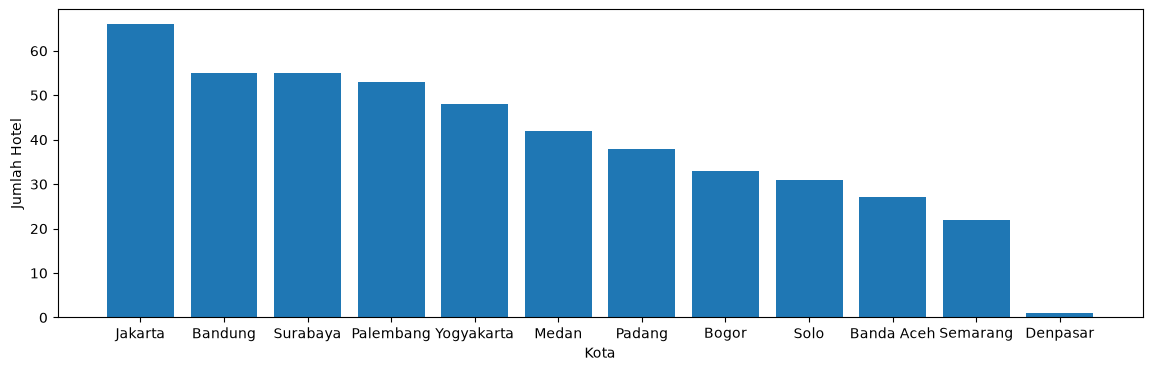

In [7]:
hotel_per_kota = hotel_per_kota.sort_values('jumlah_hotel', ascending=False)
plt.figure(figsize=(14,4))
plt.bar(hotel_per_kota['city'], hotel_per_kota['jumlah_hotel'])
plt.xlabel('Kota')
plt.ylabel('Jumlah Hotel')
plt.show()

# Menggunakan library matplotlib untuk memvisualisasikan persebaran hotel berdasarkan kota

- Jakarta menempati urutan pertama hotel terbanyak yaitu 66 hotel dan diikuti oleh Bandung dan Surabaya sebanyak 55
- Denpasar hanya memiliki 1 hotel yang menjadikan nya kota dengan jumlah hotel paling sedikit
- Semarang 22 hotel dan Banda Aceh 27 hotel
- Kesimpulan sementara persebaran jumlah hotel berdasarkan kota tidak merata. Kota-kota besar memiliki jumlah akomodasi lebih banyak daripada kota lain.

Insight
- Persebaran hotel didominasi oleh kota-kota besar seperti Jakarta, Bandung, Surabaya, dan Palembang. Mengindikasikan bahwa wilayah tersebut memiliki penawaran akomodasi yang lebih beragam selama periode tahun baru.
- Kota dengan jumlah hotel yang sangat sedikit memiliki representasi data yang terbatas sehingga hasil analisis tarif pada kota tersebut sebaiknya tidak digeneralisasi.

In [ ]:
''' 2. Bagaimana komposisi hotel berdasarkan starrating?'''

star_rating = (
    df.groupby('star_rating')['name']
    .nunique()
    .reset_index(name='jumlah_hotel')
    .sort_values('star_rating'))
star_rating

,star_rating,jumlah_hotel
0,0.0,49
1,1.0,33
2,1.5,6
3,2.0,59
4,2.5,3
5,3.0,118
6,3.5,8
7,4.0,135
8,5.0,60


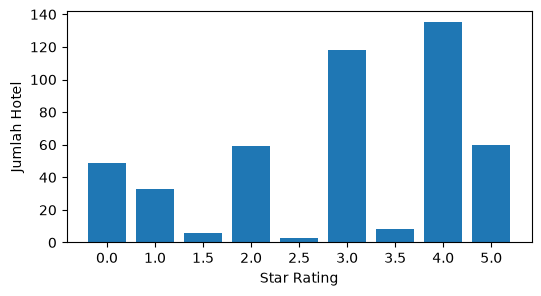

In [9]:
plt.figure(figsize=(6,3))
plt.bar(star_rating['star_rating'].astype(str), star_rating['jumlah_hotel'])
plt.xlabel('Star Rating')
plt.ylabel('Jumlah Hotel')
plt.show()

- Terdapat angka yang cukup besar (49) pada jumlah hotel dengan rating 0.
- Terdapat 118 hotel berbintang 3 dan 135 hotel berbintang 4 yang artinya sebagian besar akomodasi dalam dataset terkonsentrasi pada kelas menengah ke atas
- Hotel dengan rating 0 diasumsikan sebagai akomodasi yang belum diklasifikasi/tidak bersistem peringkat bintang

Insight
Dominasi hotel bintang 3 dan 4 menunjukan bahwa penawaran hotel pada periode tahun baru lebih banyak berada pada segmen menengah, sehingga kategori ini menjadi pasar utama yang dapat menjadi fokus dalam evaluasi strategi harga

In [ ]:
''' 3. Kota mana yang hotel per malamnya memiliki median tarif tertinggi?'''

harga_median =(
    df.groupby('city')['cheapest_rate_pern']
    .median()
    .reset_index(name='median_tarif')
    .sort_values('median_tarif', ascending=False)
)
harga_median.head(10)

,city,median_tarif
11,Yogyakarta,1805918.5
4,Jakarta,1625000.0
1,Bandung,1520340.0
8,Semarang,1100789.0
2,Bogor,1017250.0
10,Surabaya,795333.0
9,Solo,700000.0
6,Padang,522350.0
3,Denpasar,455050.0
0,Banda Aceh,440000.0


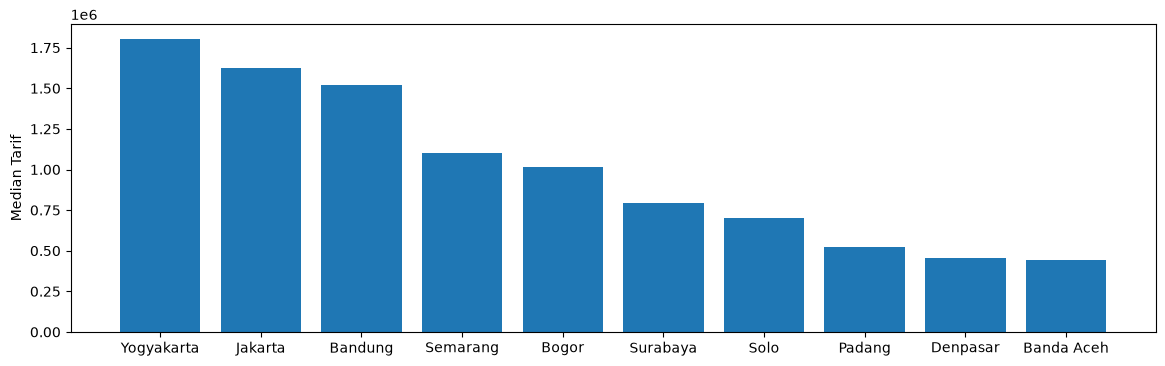

In [11]:
top_10 = harga_median.head(10)
plt.figure(figsize=(14,4))
plt.bar(top_10['city'], top_10['median_tarif'])
plt.ylabel('Median Tarif')
plt.show()

- Yogyakrta memiliki median tarif termurah per malam tertinggi yaitu Rp 1.81jt, lebih tinggi dibanding kota lain.
- Jakarta dan Bandung termasuk kota dengan median tarif termurah per malam yang tinggi. yang mengindikasikan positioning harga hotel yang lebih tinggi selama periode tahun baru
- Ditemukan selisih median yang cukup besar antar kota. Diamana Banda Aceh dengan tarif Rp 440k sedangkan Yogyakarta mencapai Rp 1.81jt
- Median pada kota Denpasar dihitung hanya dari satu hotel  yang tersedia dari dataset, sehingga hasilnya lebih menggambarkan kondisi sampel yang dikumpulkan daripada keseluruhan hotel di kota tersebut.
- Median dipilih karena terdapat outlier pada informasi df.describe kolom cheapest_rate_pern

Insight
Yogyakarta memiliki median tarif hotel per malam tertinggi sebesar Rp. 1,81 juta, diikuti Jakarta dan Bandung, yang menunjukan tarif hotel cenderung lebih tinggi di kota-kota tersebut selam periode tahun baru. Perbedaan median antar kota juga cukup besar sehingga median digunakan sebagai ukuran pemusatan karena distribusi tarif mengandung oulier. Denpasar tidak dijadikan acuan umum karena hanya memiliki satu hotel pada dataset

In [ ]:
''' 5. Bagaimana karakteristik distribusi tarif hotel per malam selama selama periode tahun baru?'''

df['cheapest_rate_pern'].describe()

count    9.040000e+02
mean     1.364033e+06
std      1.747131e+06
min      5.827400e+04
25%      4.641502e+05
50%      9.726040e+05
75%      1.646725e+06
max      2.794400e+07
Name: cheapest_rate_pern, dtype: float64

In [24]:
df['cheapest_rate_pern'].median()

np.float64(972604.0)

median dari cheapest_rate_pern adalah Rp 972.604 yang mana separuh hotel menawarkan tarif di bawah Rp 972k per malam dan separuh lain nya berada di atas nilai tersebut

In [25]:
df['cheapest_rate_pern'].skew()

np.float64(7.715760582657408)

- Skewness dari cheapest_rate_pern adalah 7.72 yang mana menunjukan distribusi tarif cenderung kuat ke arah kanan.
- Mengindikasikan sebagian besar hotel bertarif di range rendah hingga menenga, sementara sebagian kecilnya menawarkan tarif yang sangat tinggi

In [26]:
df['cheapest_rate_pern'].kurt()

np.float64(99.35934052960062)

- Angka kurtosis sebesar 99.36 menunjukan puncak yang sangat tajam dan ekor kanan yang panjang. 
- Diindikasikan adanya outlier pada tarif hotel

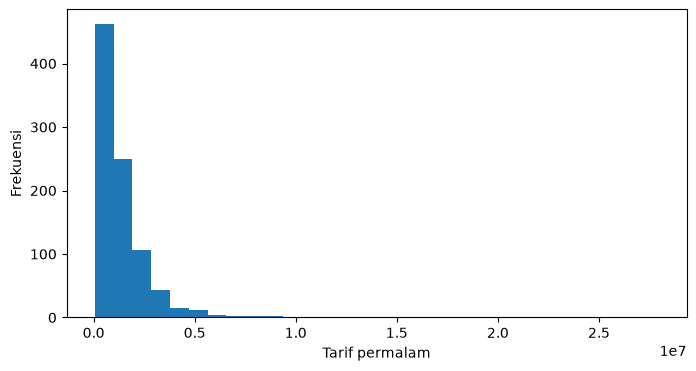

In [29]:
plt.figure(figsize=(8,4))
plt.hist(df['cheapest_rate_pern'],
         bins=30)
plt.xlabel('Tarif permalam')
plt.ylabel('Frekuensi')
plt.show()

- Histogram di atas menunjukan mayoritas hotel memiliki tarif hotel per malam yang berpusat di kisaran tarif yang relatif rendah.
- Frekuensi hotel semakin berkurang seiring meningkatnya tarif, sehingga membentuk distribusi yang memanjang ke arah kanan.
- Temuan di atas selaras dengan nilai skewness yang tinggi dan menunjukan hanya sedikit hotel yang memiliki tarif jauh kebih mahal dibanding mayoritas hotel

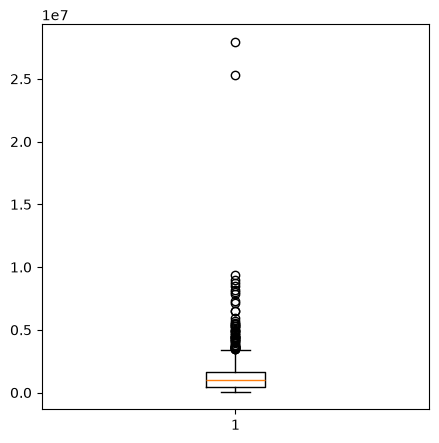

In [30]:
plt.figure(figsize=(5,5))
plt.boxplot(df['cheapest_rate_pern'])
plt.show()

- Titik-titiknya berbaris di atas batas whisker atas, yang menunjukan adanya outlier.
- Beberapa hotel memiliki tarif yang jauh lebih tinggi dibanding sebagian besar hotel lain.
- Outlier mempengaruhi nilai rata-rata

Insight
Berdasarkan statistik deskriptif, histogram dan boxplot, distribusi tarif termurah per malam selama periode tahun baru tidak berdistribusi normal dan cenderung ke arah kanan. Mayoritas hotel menawarkan tarif pada kisarana yang relatif lebih rendah, sementara hanya sebagian kecil hotel yang memiliki tarif sangat tinggi. Kemunculan outlier menyebabakan rata-rata ditarik oleh nilai ekstrem, sehingga median lebih tepat digunakan sebagai tolak ukur dalam analisis tarif hotel

In [ ]:
''' 6. Apakah terdapat perbedaan tarif hotel per malam yang signifikan berdasarkan star rating?
H0: Data berdistribusi normal
H1: Data tidak berdistribusi normal
Tingkat signifikansi 5%'''

for rating in sorted(df['star_rating'].dropna().unique()):
    stat, p = shapiro(
        df[df['star_rating']==rating]['cheapest_rate_pern']
    )
    print(rating, p)

0.0 2.4720942218704506e-18
1.0 1.3237243868982116e-07
1.5 0.41479450769282233
2.0 2.3604302973709622e-18
2.5 0.07189259489319819
3.0 8.580350077532864e-17
3.5 0.002657528601875014
4.0 3.9861897392660805e-16
5.0 6.165834513810531e-18


Dari uji normalitas shapiro di atas menunjukan sebagian besar kelompok memiliki p-value < 0.005 shingga tidak memenuhi asumsi normalitas. Hanya kelompok hotel dengan star rating 1.5 dan 2.5 yang berdistribusi normal. Oleh karena itu, analisis perbedaan tarif hotel per malam berdasarkan star rating dilakukan menggunakan uji non-parametrik kruskal-walls mengingat syarat ANOVA datanya harus normal. 

In [18]:
kelompok = [
    df[df['star_rating'] == rating]['cheapest_rate_pern'].dropna()
    for rating in sorted(df['star_rating'].dropna().unique())]

In [19]:
# Kruskal Test
stat, p = kruskal(*kelompok)
print('stat:', stat)
print('p-value:', p)

'''
H0: Median tarif hotel per malam sama untuk semua rating
H1: Salah satu star rating memiliki tarif hotel per malam berbeda
'''

stat: 613.1149509380168
p-value: 3.5434102155630194e-127


'\nH0: Median tarif hotel per malam sama untuk semua rating\nH1: Salah satu star rating memiliki tarif hotel per malam berbeda\n'

- Hail dari test di atas adalah menolak H0
- Output dari test adalah nilai statistik sebesar 613.115 dengan p-value kurang dari 0.05
- Menunjukan bahwa terdapat perbedaan yang signifikan pada median tarif hotel per malam antar kelompok star rating
- Disimpulkan bahwa tingkat bintang hotel berpengaruh terhadap perbedaan tarif hotel permalam selama periode tahun baru

In [24]:
''' 7. Seberapa besar perbedaan antara original rate dan cheapest rate yang ditawarkan?'''

df['selisih'] = ((df['original_pern'] - df['cheapest_rate_pern'])/df['original_pern']) * 100

In [25]:
df['selisih'].describe()

count    904.000000
mean      24.427255
std        6.836213
min        1.456494
25%       24.999959
50%       25.000000
75%       25.000020
max       70.000000
Name: selisih, dtype: float64

- Rata-rata hotel menawarkan diskon sekitar 24.43% dari harga awal
- 50% hotel memiliki diskon =< 25% dan 50% lain nya => 25%
- Variasi persentase diskon relatif kecil
- diskon terkecil sekitar 1.46%
- diskon terbesar mencapai 70%

In [26]:
df['selisih'].mean()

np.float64(24.427255141299177)

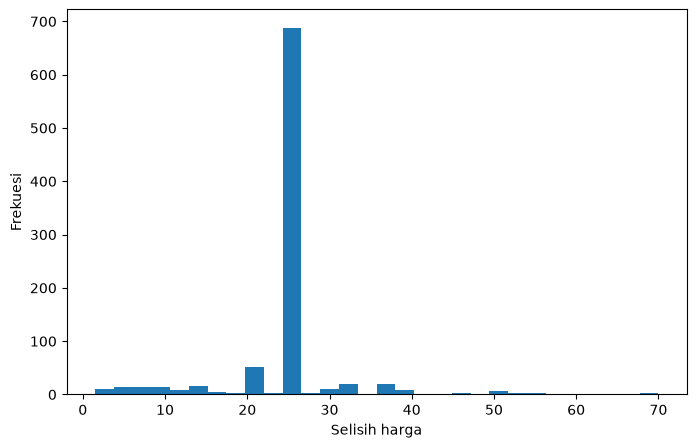

In [27]:
plt.figure(figsize=(8,5))
plt.hist(df['selisih'],
         bins=30)
plt.xlabel('Selisih harga')
plt.ylabel('Frekuesi')
plt.show()

- Sebagian besar hotel menawarkan diskon sekitar 25%, terlihat dari batang yang sangat tinggi di sekitar 25
- Distribusi condong ke kanan karena terdapat sebagian kecil hotel yang memberikan diskon jauh lebih besar hingga 70%
- diskon 25% merupakan pola yang paling umum, sedangkan diskon di range 40-70% cukup jarang

Insight
Mayoritas hotel menawarkan diskon sekitar 25% dari harga originalnya selam periode tahun baru. Hal ini terlihat dari median sebesar 25% dan histogram menunjukan pemusatan data di kisaran tersebut. Rata-rata diskon sebesar 24.43% juga sangar dekat dengan median, menandakan bahwa sebagian besar hotel memberikan besaran diskon yang relatif seragam. Meskipun demikian, terdapat sejumlah kecil hotel yang menawarkan diskon jauh lebih besar hingga 70% sehingga distribusi persentase diskon menjadi condong ke kanan.

In [33]:
print(df.duplicated())

0      False
1      False
2      False
3      False
4      False
       ...  
899    False
900    False
901    False
902    False
903    False
Length: 904, dtype: bool
